# 03 · Target label budget

**Question.** Starting from a model trained on another system (source), how many expert labels from the new system (target) are needed to approach the local model?

For each target (always separately) and each n (target labels, in total, not per class):
- **source + random**: 100 per class from the source plus n target events drawn at random;
- **source + active**: the same, but the n events are chosen by active learning (smallest margin |p(LP)−0.5|);
- **target only**: n target events drawn at random, without the source;
- **local model**: up to 100 per class from the target (ceiling, horizontal line).

The lines are the median over sources of the mean Gm over repetitions; the band is the interquartile range over sources. Source file: `../resultados/presupuesto_resumen.csv` (generated with `scripts/resumir_presupuesto.py`).

Complete results: 10 targets (systems with at least 50 LP and 50 VT), 9 sources each, 3 repetitions. Where the target pool has fewer than 200 events (Cascade, Ruiz-Olleta), the largest n uses the whole pool.

> **Note**: below 200 events, XGBoost "target only" uses a fixed small-data configuration (200 trees, depth 3, learning rate 0.1, no minimum child weight or L1 penalty). The remaining Gm = 0 values of "target only" are real: in strongly imbalanced targets (Villarrica, 31,483 LP vs 308 VT; Laguna del Maule at n = 10) a random draw of n events contains a single class.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

# English display names for the systems (the data files keep the Spanish names)
SYSTEM_EN = {"Hawái": "Hawai`i", "Norte de California": "Northern California",
             "Nevados de Chillan": "Nevados de Chillán", "Decepcion": "Deception Island",
             "Decepcion95": "Deception Island 1995", "Decepcion09": "Deception Island 2009",
             "Popocatepetl": "Popocatépetl"}

def en(df, cols=("sistema", "fuente", "destino")):
    """Replace system names by their English display names in the given columns."""
    df = df.copy()
    for c in cols:
        if c in df:
            df[c] = df[c].replace(SYSTEM_EN)
    return df
r = en(pd.read_csv(RES / "presupuesto_resumen.csv"))
print(r.groupby("destino").fuente.nunique().rename("n_sources").to_string())

destino
Alaska                 9
Cascade                9
Copahue                9
Hawai`i                9
Hudson                 9
Laguna del Maule       9
Nevados de Chillán     9
Northern California    9
Ruiz-Olleta            9
Villarrica             9


In [2]:
ESTILO = {"azar": ("source + random", "#3b75af", "-"), "activo": ("source + active", "#c0392b", "-"),
          "solo_destino": ("target only", "#555555", "--")}
NOMBRE = {"log": "Logistic regression", "xgb": "XGBoost", "tabpfn": "TabPFN"}
destinos = sorted(r.destino.unique())

def curvas(modelo):
    g = r[r.modelo == modelo]
    fig, ejes = plt.subplots(2, int(np.ceil(len(destinos) / 2)), figsize=(12, 6), sharey=True)
    for ax, dst in zip(ejes.flat, destinos):
        h = g[g.destino == dst]
        for sel, (lab, col, ls) in ESTILO.items():
            q = h[h.seleccion == sel].groupby("n").gm.quantile([.25, .5, .75]).unstack()
            if q.empty:
                continue
            ax.plot(q.index, q[.5], ls, color=col, marker="o", ms=3, label=lab)
            ax.fill_between(q.index, q[.25], q[.75], color=col, alpha=.15)
        loc = h[h.seleccion == "local"].gm.median()
        if np.isfinite(loc):
            ax.axhline(loc, color="g", lw=1, ls=":", label="local model")
        ax.set_xscale("symlog", linthresh=10); ax.set_xlim(-0.5, 230); ax.set_xticks([0, 10, 20, 50, 100, 200])
        ax.set_xticklabels([0, 10, 20, 50, 100, 200])
        ax.set_title(f"{dst} ({h.fuente.nunique()} sources)"); ax.grid(alpha=.3); ax.set_ylim(0, 1)
    for ax in ejes.flat[len(destinos):]:
        ax.axis("off")
    for ax in ejes[-1]:
        ax.set_xlabel("n target labels")
    for ax in ejes[:, 0]:
        ax.set_ylabel("Gm")
    ejes.flat[0].legend(fontsize=7, loc="lower right")
    fig.suptitle(NOMBRE[modelo]); fig.tight_layout()

## Logistic regression

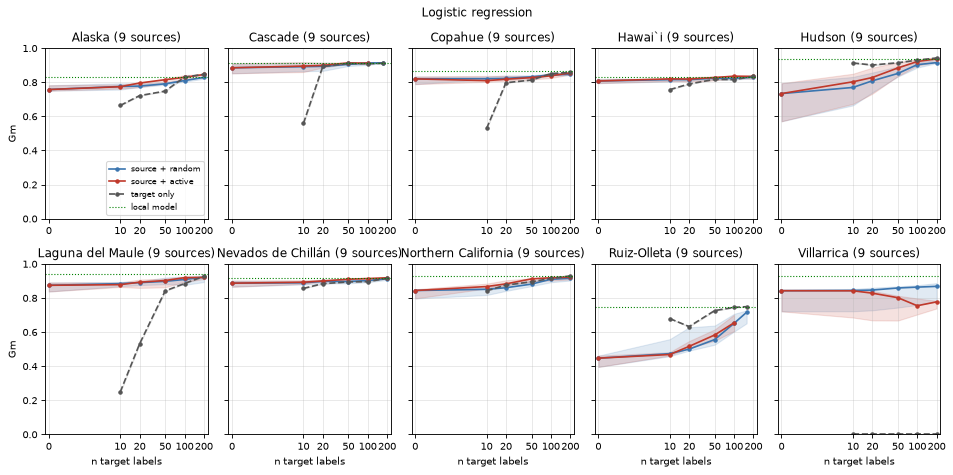

In [3]:
curvas("log")

## XGBoost


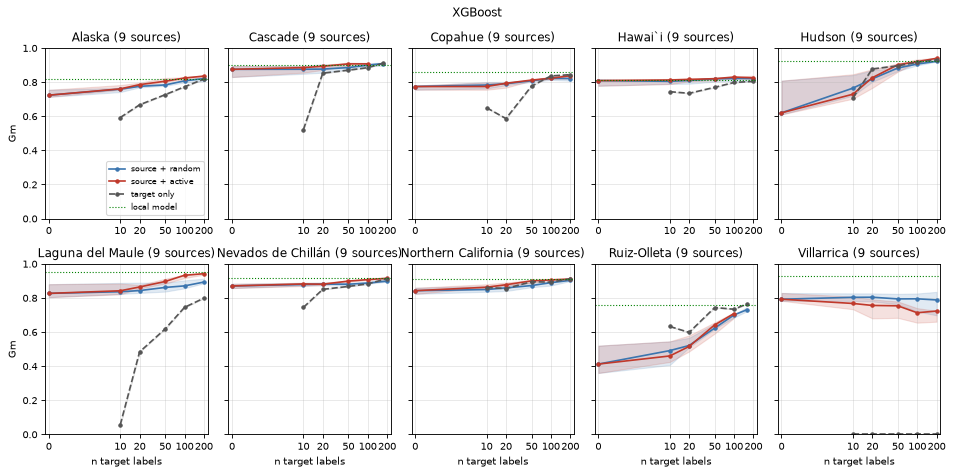

In [4]:
curvas("xgb")

## TabPFN

Random selection only (no active learning).

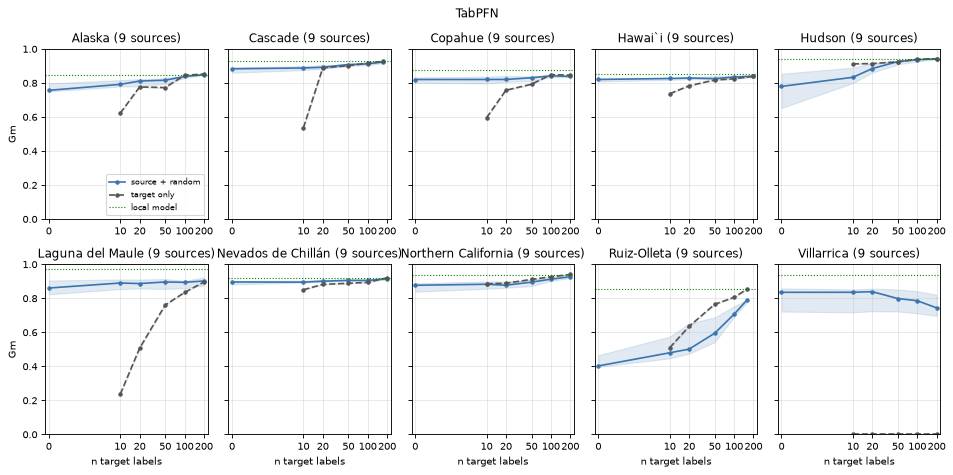

In [5]:
curvas("tabpfn")

## Table: median over sources of Gm, by target, model, selection and n

In [6]:
t = (r[r.seleccion != "local"].groupby(["destino", "modelo", "seleccion", "n"]).gm.median()
     .unstack("n").round(3))
t

n                                 0      10     20     50     100  157  174    200
destino    modelo seleccion                                                       
Alaska     log    activo        0.758  0.774  0.796  0.815  0.829  NaN  NaN  0.846
                  azar          0.758  0.775  0.778  0.791  0.810  NaN  NaN  0.829
                  solo_destino    NaN  0.664  0.722  0.748  0.830  NaN  NaN  0.847
           tabpfn azar          0.757  0.792  0.811  0.816  0.838  NaN  NaN  0.848
                  solo_destino    NaN  0.622  0.777  0.773  0.845  NaN  NaN  0.853
...                               ...    ...    ...    ...    ...  ...  ...    ...
Villarrica tabpfn azar          0.835  0.835  0.839  0.799  0.786  NaN  NaN  0.744
                  solo_destino    NaN  0.000  0.000  0.000  0.000  NaN  NaN  0.000
           xgb    activo        0.793  0.768  0.756  0.754  0.713  NaN  NaN  0.723
                  azar          0.793  0.804  0.804  0.794  0.795  NaN  NaN  0.788
                  solo_destino    NaN  0.000  0.000  0.000  0.000  NaN  NaN  0.000

[80 rows x 8 columns]